# Analisis Sentimen Ulasan Aplikasi blu by BCA

| Skema | Algoritma (Deep Learning) | Ekstraksi Fitur | Split (train/val/test) |
|---|---|---|---|
| 1 | Bidirectional LSTM | Tokenizer + Embedding (sequence) | 80/10/10 |
| 2 | CNN 1D | Tokenizer + Embedding (sequence) | 70/15/15 |
| 3 | MLP (Dense) | TF-IDF (unigram+bigram) | 80/10/10 |

In [ ]:
import os, re, pickle, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)

if not os.path.isdir('resources'):
    zipfile.ZipFile('resources.zip').extractall('.')
print('TensorFlow', tf.__version__, '| resources:', sorted(os.listdir('resources')))

TensorFlow 2.21.0 | resources: ['lexicon.txt', 'phrases.txt', 'slang.txt', 'stopwords.txt']


## 1. Validasi & Cleaning Data
Memeriksa struktur, nilai kosong, dan duplikat, lalu membersihkannya.

In [ ]:
DATA_PATH = 'dataset_ulasan_blubca.csv'
df_raw = pd.read_csv(DATA_PATH)
print('Shape awal  :', df_raw.shape)
print('Kolom       :', list(df_raw.columns))
print('Missing     :\n', df_raw.isna().sum())
print('Duplikat    :', df_raw.duplicated(subset='ulasan').sum())
print('\nDistribusi rating asli (kolom label):')
print(df_raw['label'].value_counts().sort_index())
df_raw.head()

Shape awal  : (12000, 2)
Kolom       : ['ulasan', 'label']
Missing     :
 ulasan    0
label     0
dtype: int64
Duplikat    : 15

Distribusi rating asli (kolom label):
label
1    3887
2    1019
3    1217
4    1064
5    4813
Name: count, dtype: int64


,ulasan,label
0,"Mohon diperbaiki, iklan poster eventnya sangat...",2
1,"mau log in aja muter lama banget, bilang sambu...",1
2,aplikasi blu kalau keluar dan login kembali fi...,1
3,"terlalu berbelit-belit, konfirmasi nya harus V...",1
4,"Hei blu, ini saya ada gangguan di hp mengakiba...",3


In [ ]:
df = df_raw.copy()
df = df.dropna(subset=['ulasan'])
df['ulasan'] = df['ulasan'].astype(str).str.strip()
df = df[df['ulasan'].str.len() >= 3]
df = df.drop_duplicates(subset='ulasan').reset_index(drop=True)
df = df.rename(columns={'label': 'rating'})
df = df[df['rating'].between(1, 5)].reset_index(drop=True)
print('Shape setelah cleaning:', df.shape)
assert len(df) >= 10000, 'Data kurang dari 10.000 sampel!'

Shape setelah cleaning: (11985, 2)


## 2. Normalisasi Teks (sebelum pelabelan)

Teks dinormalisasi lebih dulu agar pelabelan tidak keliru membaca angka, URL, emoji, huruf berulang, atau
bahasa tidak baku sebagai sentimen. Kamus slang, leksikon sentimen, frasa, dan stopword disimpan di file `.txt`
pada folder `resources/` agar kode tetap ringkas dan mudah dibaca.

In [ ]:
def read_pairs(path, sep, cast=str):
    pairs = {}
    with open(path, encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line and not line.startswith('#'):
                key, value = line.split(sep, 1)
                pairs[key.strip()] = cast(value.strip())
    return pairs

SLANG = read_pairs('resources/slang.txt', '=')                       # kata tidak baku -> baku
LEXICON = read_pairs('resources/lexicon.txt', ',', int)              # kata -> bobot sentimen
PHRASES = {tuple(k.split()): v for k, v in read_pairs('resources/phrases.txt', ',', int).items()}
STOPWORDS = set(open('resources/stopwords.txt', encoding='utf-8').read().split())
NEGATIONS = {'tidak', 'bukan', 'belum', 'jangan'}                    # kata negasi (membalik polaritas)
PHRASE_WORDS = {w2 for (_, w2) in PHRASES}                           # kata kedua pada frasa sentimen

def normalize(text):
    t = str(text).lower()
    t = re.sub(r'https?://\S+|www\.\S+', ' ', t)
    t = re.sub(r'@\w+|#\w+', ' ', t)
    t = re.sub(r'[^a-z\s]', ' ', t)
    t = re.sub(r'(.)\1{2,}', r'\1', t)
    tokens = []
    for tok in t.split():
        tokens.extend(SLANG.get(tok, tok).split())
    return tokens

print('Kamus slang:', len(SLANG), '| leksikon:', len(LEXICON), '| frasa:', len(PHRASES), '| stopword:', len(STOPWORDS))
print(normalize('Aplikasinya baguuus bgt, gak pernah error!! http://x.co'))

Kamus slang: 91 | leksikon: 127 | frasa: 7 | stopword: 68
['aplikasi', 'bagus', 'banget', 'tidak', 'pernah', 'galat']


## 3. Labeling (Negatif / Netral / Positif)

Kolom `label` pada dataset adalah **rating bintang (1-5)**, bukan sentimen, dan isinya noisy
(ulasan berisi keluhan tetapi berbintang 4-5). Pelabelan dilakukan dengan **leksikon sentimen domain**
(bahasa Indonesia, topik aplikasi perbankan) + penanganan negasi dan frasa ("tidak bisa").

Catatan validasi: leksikon InSet mentah sempat diuji dan ditolak karena polaritas kata umum terbalik
(mis. "bagus" negatif), yang membuat 90% data berlabel negatif. Leksikon domain divalidasi dengan
membandingkan label terhadap rating asli (tabel crosstab di bawah).

In [ ]:
def lexicon_score(tokens):
    score, i = 0, 0
    while i < len(tokens):
        if i + 1 < len(tokens) and (tokens[i], tokens[i+1]) in PHRASES:
            score += PHRASES[(tokens[i], tokens[i+1])]; i += 2; continue
        w = LEXICON.get(tokens[i])
        if w:
            if i > 0 and tokens[i-1] in NEGATIONS: w = -w
            score += w
        i += 1
    return score

def to_label(score):
    return 'positif' if score > 0 else ('negatif' if score < 0 else 'netral')

assert LEXICON['bagus'] > 0 and LEXICON['lambat'] < 0 and LEXICON['kecewa'] < 0, 'Polaritas leksikon salah!'
df['skor'] = df['ulasan'].map(lambda s: lexicon_score(normalize(s)))
df['sentimen'] = df['skor'].map(to_label)
dist = df['sentimen'].value_counts(normalize=True).round(3)
print(dist)
print('Baseline tebak kelas mayoritas:', dist.max())
assert dist.min() > 0.05 and dist.max() < 0.75, 'Distribusi kelas terlalu timpang - periksa leksikon!'
print('Validasi label vs rating asli (proporsi per baris):')
display(pd.crosstab(df['rating'], df['sentimen'], normalize='index').round(2))
df[['ulasan','rating','skor','sentimen']].sample(8, random_state=SEED)

sentimen
negatif    0.482
positif    0.374
netral     0.143
Name: proportion, dtype: float64
Baseline tebak kelas mayoritas: 0.482
Validasi label vs rating asli (proporsi per baris):


sentimen,negatif,netral,positif
rating,,,
1,0.79,0.14,0.07
2,0.75,0.15,0.10
3,0.66,0.18,0.16
4,0.43,0.18,0.39
5,0.14,0.13,0.73


,ulasan,rating,skor,sentimen
1470,"Aplikasi Bank Digital terburuk yang aku tau, a...",3,1,positif
10949,Blu terhenti terus.gak bisa login,1,-3,negatif
5566,aku kasih 1 dulu ya karena penilaian bca kepad...,1,0,netral
7510,"Lemot bangetttt,simpel aja dong jangan banyak ...",5,-1,negatif
554,Kadang login masuk gagal terus. Kalau gini aca...,2,-12,negatif
10906,"bagus,walau fiture nya sedikit ngelag",5,0,netral
2473,"aplikasi sampah, verikasi foto tidak bisa di k...",1,-13,negatif
932,"Transfer pakai biFast sudah bisa. Please min, ...",4,-2,negatif


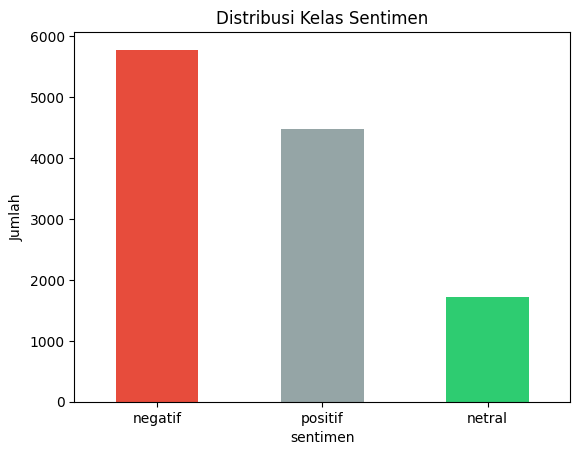

In [7]:
df['sentimen'].value_counts().plot(kind='bar', color=['#e74c3c','#95a5a6','#2ecc71'], title='Distribusi Kelas Sentimen')
plt.ylabel('Jumlah'); plt.xticks(rotation=0); plt.show()
assert df['sentimen'].nunique() == 3, 'Harus ada 3 kelas'

## 4. Preprocessing

Setelah pelabelan, teks diubah menjadi input model.

- `FOCUS_INPUT = True` (default): input model hanya kata pembawa sentimen + negasi + penanda jeda setelah negasi. Ini feature selection berbasis leksikon: model fokus pada sinyal sentimen dan tidak menghafal ribuan kata lain. Konsekuensinya, akurasi mengukur seberapa baik model meniru aturan pelabelan leksikon.
- `FOCUS_INPUT = False`: seluruh teks ulasan (stopword dibuang) dipakai sebagai input. Hasil percobaan ini bisa dilaporkan sebagai pembanding (ablation).

Stemming tidak dipakai karena label dibuat dari kata asli; stemming mengubah kata sehingga tidak lagi cocok dengan leksikon.

In [ ]:
FOCUS_INPUT = True
KEEP_TOKENS = set(LEXICON) | NEGATIONS | PHRASE_WORDS

def focus_tokens(tokens):
    out, gap_added = [], False
    for i, t in enumerate(tokens):
        if t in KEEP_TOKENS:
            out.append(t); gap_added = False
        elif out and out[-1] in NEGATIONS and not gap_added and i > 0 and tokens[i-1] == out[-1]:
            out.append('sela'); gap_added = True
    return ' '.join(out) if out else 'kosong'

def preprocess(text):
    tokens = normalize(text)
    if FOCUS_INPUT:
        return focus_tokens(tokens)
    kept = [t for t in tokens if t in KEEP_TOKENS or (t not in STOPWORDS and len(t) > 1)]
    return ' '.join(kept)

df['clean'] = df['ulasan'].map(preprocess)
df = df[df['clean'].str.strip().str.len() > 0].reset_index(drop=True)
print('Jumlah data akhir:', len(df))
df[['ulasan','clean','sentimen']].head(5)

Jumlah data akhir: 11985


,ulasan,clean,sentimen
0,"Mohon diperbaiki, iklan poster eventnya sangat...",diperbaiki mengganggu lambat lambat aman diper...,negatif
1,"mau log in aja muter lama banget, bilang sambu...",masuk muter lama putus baik tidak bisa masuk b...,negatif
2,aplikasi blu kalau keluar dan login kembali fi...,masuk sulit jelas tidak sela gagal masuk stabi...,negatif
3,"terlalu berbelit-belit, konfirmasi nya harus V...",tidak masalah ada susah bisa,negatif
4,"Hei blu, ini saya ada gangguan di hp mengakiba...",ada gangguan tidak ada masuk trouble bisa masuk,negatif


## 5. Train / Validation / Test Split (stratified)
Split dilakukan sebelum ekstraksi fitur; Tokenizer dan TF-IDF hanya di-fit pada data train (tanpa data leakage).

In [ ]:
le = LabelEncoder()
y_all = le.fit_transform(df['sentimen'])          # urutan alfabet: negatif=0, netral=1, positif=2
CLASS_NAMES = list(le.classes_)
texts = df['clean'].values
print('Kelas:', CLASS_NAMES)

def split_data(train, val, test):
    idx = np.arange(len(texts))
    i_tr, i_tmp = train_test_split(idx, test_size=1 - train, stratify=y_all, random_state=SEED)
    i_va, i_te = train_test_split(i_tmp, test_size=test / (val + test), stratify=y_all[i_tmp], random_state=SEED)
    return (texts[i_tr], texts[i_va], texts[i_te], y_all[i_tr], y_all[i_va], y_all[i_te], i_te)

Kelas: ['negatif', 'netral', 'positif']


## 6. Feature Extraction & Fungsi Training/Evaluasi

In [ ]:
def seq_features(X_tr, X_va, X_te):
    tok = Tokenizer(oov_token='<OOV>')
    tok.fit_on_texts(X_tr)
    maxlen = int(np.percentile([len(s.split()) for s in X_tr], 95))
    f = lambda X: pad_sequences(tok.texts_to_sequences(X), maxlen=maxlen, padding='post', truncating='post')
    return f(X_tr), f(X_va), f(X_te), tok, maxlen

results = {}      # ringkasan tiap skema
predictors = {}   # fungsi inference tiap skema

def train_and_eval(name, model, Xtr, ytr, Xva, yva, Xte, yte, idx_te, epochs=40, batch_size=64, use_cw=False):
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    cw = dict(enumerate(compute_class_weight('balanced', classes=np.unique(ytr), y=ytr))) if use_cw else None
    es = callbacks.EarlyStopping(monitor='val_accuracy', patience=6, restore_best_weights=True)
    rl = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=0)
    hist = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs, batch_size=batch_size,
                     class_weight=cw, callbacks=[es, rl], verbose=2)
    tr_acc = accuracy_score(ytr, model.predict(Xtr, verbose=0).argmax(1))
    va_acc = accuracy_score(yva, model.predict(Xva, verbose=0).argmax(1))
    pred_te = model.predict(Xte, verbose=0).argmax(1)
    te_acc = accuracy_score(yte, pred_te)
    print(f'\n[{name}] Train acc={tr_acc:.4f} | Val acc={va_acc:.4f} | Test acc={te_acc:.4f}')
    print(classification_report(yte, pred_te, target_names=CLASS_NAMES, digits=4))
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    ax[0].plot(hist.history['accuracy'], label='train'); ax[0].plot(hist.history['val_accuracy'], label='val')
    ax[0].set_title(f'{name} - Accuracy'); ax[0].legend()
    ax[1].plot(hist.history['loss'], label='train'); ax[1].plot(hist.history['val_loss'], label='val')
    ax[1].set_title(f'{name} - Loss'); ax[1].legend()
    sns.heatmap(confusion_matrix(yte, pred_te), annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[2])
    ax[2].set_title('Confusion Matrix (Test)'); ax[2].set_xlabel('Prediksi'); ax[2].set_ylabel('Aktual')
    plt.tight_layout(); plt.show()
    results[name] = dict(train_acc=tr_acc, val_acc=va_acc, test_acc=te_acc,
                         f1=f1_score(yte, pred_te, average='macro'),
                         model=model, pred=pred_te, y_te=yte, idx_te=idx_te)
    return model

def make_seq_predictor(model, tok, maxlen):
    def predict(text):
        x = pad_sequences(tok.texts_to_sequences([preprocess(text)]), maxlen=maxlen, padding='post', truncating='post')
        p = model.predict(x, verbose=0)[0]
        return CLASS_NAMES[int(p.argmax())], p
    return predict

## 7. Skema 1 — Bidirectional LSTM + Tokenizer/Embedding (split 80/10/10)

Split 80/10/10 -> 9588 1198 1199


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 9, 128)         │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 9, 128)         │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 124,675 (487.01 KB)

 Trainable params: 124,675 (487.01 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
150/150 - 9s - 58ms/step - accuracy: 0.8060 - loss: 0.4978 - val_accuracy: 0.9140 - val_loss: 0.2451 - learning_rate: 0.0010
Epoch 2/40
150/150 - 1s - 8ms/step - accuracy: 0.9301 - loss: 0.2143 - val_accuracy: 0.9332 - val_loss: 0.1887 - learning_rate: 0.0010
Epoch 3/40
150/150 - 1s - 8ms/step - accuracy: 0.9392 - loss: 0.1885 - val_accuracy: 0.9357 - val_loss: 0.1666 - learning_rate: 0.0010
Epoch 4/40
150/150 - 1s - 8ms/step - accuracy: 0.9427 - loss: 0.1680 - val_accuracy: 0.9466 - val_loss: 0.1554 - learning_rate: 0.0010
Epoch 5/40
150/150 - 1s - 8ms/step - accuracy: 0.9452 - loss: 0.1607 - val_accuracy: 0.9432 - val_loss: 0.1496 - learning_rate: 0.0010
Epoch 6/40
150/150 - 1s - 9ms/step - accuracy: 0.9507 - loss: 0.1444 - val_accuracy: 0.9533 - val_loss: 0.1366 - learning_rate: 0.0010
Epoch 7/40
150/150 - 2s - 12ms/step - accuracy: 0.9557 - loss: 0.1301 - val_accuracy: 0.9549 - val_loss: 0.1288 - learning_rate: 0.0010
Epoch 8/40
150/150 - 2s - 13ms/step - accuracy: 0.957

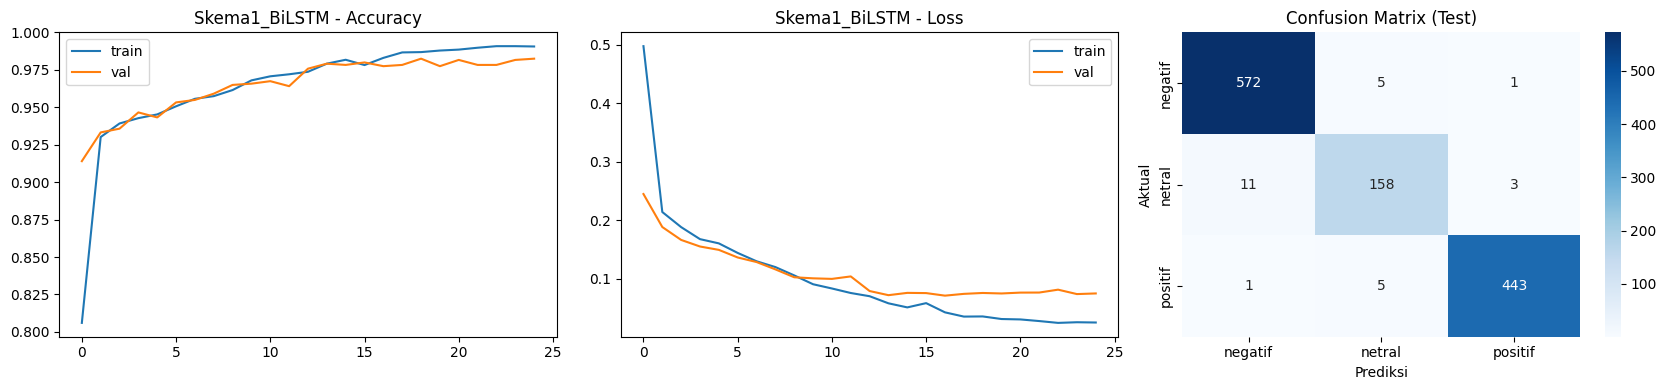

In [11]:
X_tr, X_va, X_te, y_tr, y_va, y_te, i_te = split_data(0.8, 0.1, 0.1)
print('Split 80/10/10 ->', len(X_tr), len(X_va), len(X_te))
Str, Sva, Ste, tok1, maxlen1 = seq_features(X_tr, X_va, X_te)
vocab1 = len(tok1.word_index) + 1

m1 = models.Sequential([
    layers.Input(shape=(maxlen1,)),
    layers.Embedding(vocab1, 128),
    layers.SpatialDropout1D(0.2),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dense(3, activation='softmax')])
m1.summary()
m1 = train_and_eval('Skema1_BiLSTM', m1, Str, y_tr, Sva, y_va, Ste, y_te, i_te)
predictors['Skema1_BiLSTM'] = make_seq_predictor(m1, tok1, maxlen1)

## 8. Skema 2 — CNN 1D + Tokenizer/Embedding (split 70/15/15)

Split 70/15/15 -> 8389 1798 1798


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 9, 128)         │        17,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ (None, 9, 128)         │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 5, 128)         │        82,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 107,779 (421.01 KB)

 Trainable params: 107,779 (421.01 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
132/132 - 11s - 82ms/step - accuracy: 0.7672 - loss: 0.5874 - val_accuracy: 0.9138 - val_loss: 0.2716 - learning_rate: 0.0010
Epoch 2/40
132/132 - 1s - 4ms/step - accuracy: 0.9116 - loss: 0.2728 - val_accuracy: 0.9288 - val_loss: 0.1984 - learning_rate: 0.0010
Epoch 3/40
132/132 - 0s - 4ms/step - accuracy: 0.9245 - loss: 0.2249 - val_accuracy: 0.9338 - val_loss: 0.1798 - learning_rate: 0.0010
Epoch 4/40
132/132 - 1s - 4ms/step - accuracy: 0.9306 - loss: 0.1963 - val_accuracy: 0.9433 - val_loss: 0.1599 - learning_rate: 0.0010
Epoch 5/40
132/132 - 0s - 4ms/step - accuracy: 0.9349 - loss: 0.1774 - val_accuracy: 0.9449 - val_loss: 0.1500 - learning_rate: 0.0010
Epoch 6/40
132/132 - 1s - 4ms/step - accuracy: 0.9422 - loss: 0.1609 - val_accuracy: 0.9522 - val_loss: 0.1401 - learning_rate: 0.0010
Epoch 7/40
132/132 - 0s - 4ms/step - accuracy: 0.9442 - loss: 0.1536 - val_accuracy: 0.9494 - val_loss: 0.1387 - learning_rate: 0.0010
Epoch 8/40
132/132 - 0s - 4ms/step - accuracy: 0.9492

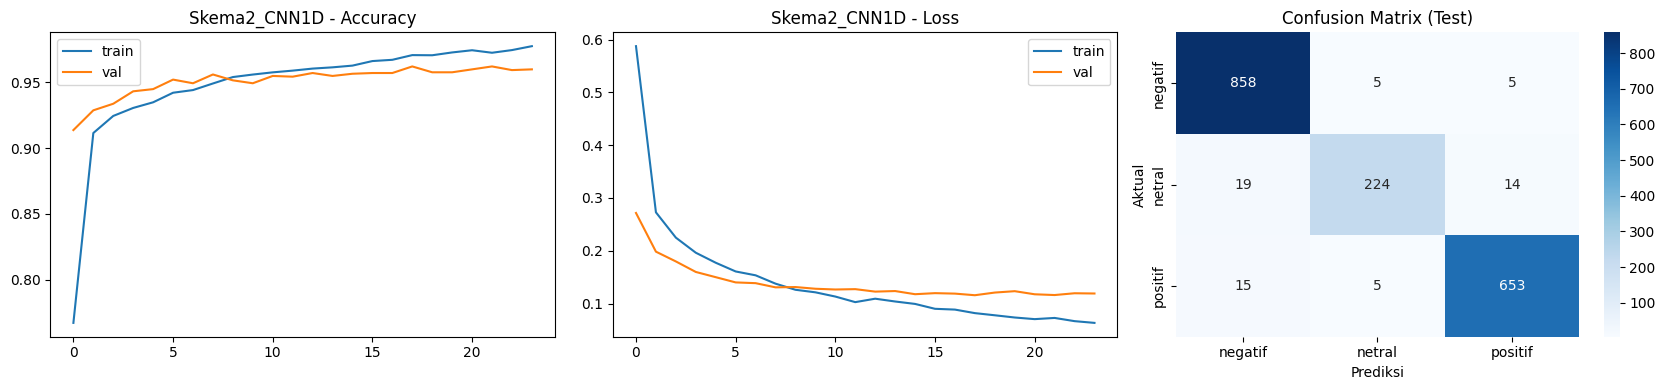

In [12]:
X_tr, X_va, X_te, y_tr, y_va, y_te, i_te = split_data(0.7, 0.15, 0.15)
print('Split 70/15/15 ->', len(X_tr), len(X_va), len(X_te))
Str, Sva, Ste, tok2, maxlen2 = seq_features(X_tr, X_va, X_te)
vocab2 = len(tok2.word_index) + 1

m2 = models.Sequential([
    layers.Input(shape=(maxlen2,)),
    layers.Embedding(vocab2, 128),
    layers.SpatialDropout1D(0.3),
    layers.Conv1D(128, 5, activation='relu'),
    layers.GlobalMaxPooling1D(),
    layers.Dropout(0.4),
    layers.Dense(64, activation='relu'),
    layers.Dense(3, activation='softmax')])
m2.summary()
m2 = train_and_eval('Skema2_CNN1D', m2, Str, y_tr, Sva, y_va, Ste, y_te, i_te)
predictors['Skema2_CNN1D'] = make_seq_predictor(m2, tok2, maxlen2)

## 9. Skema 3 — MLP + TF-IDF unigram+bigram (split 80/10/10)

TF-IDF shape: (9588, 2121)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 256)            │       543,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 559,875 (2.14 MB)

 Trainable params: 559,875 (2.14 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
150/150 - 8s - 51ms/step - accuracy: 0.7990 - loss: 0.5518 - val_accuracy: 0.9399 - val_loss: 0.1968 - learning_rate: 0.0010
Epoch 2/40
150/150 - 1s - 3ms/step - accuracy: 0.9431 - loss: 0.1750 - val_accuracy: 0.9549 - val_loss: 0.1393 - learning_rate: 0.0010
Epoch 3/40
150/150 - 1s - 3ms/step - accuracy: 0.9632 - loss: 0.1098 - val_accuracy: 0.9574 - val_loss: 0.1258 - learning_rate: 0.0010
Epoch 4/40
150/150 - 1s - 3ms/step - accuracy: 0.9778 - loss: 0.0726 - val_accuracy: 0.9549 - val_loss: 0.1209 - learning_rate: 0.0010
Epoch 5/40
150/150 - 1s - 3ms/step - accuracy: 0.9825 - loss: 0.0515 - val_accuracy: 0.9574 - val_loss: 0.1244 - learning_rate: 0.0010
Epoch 6/40
150/150 - 1s - 3ms/step - accuracy: 0.9866 - loss: 0.0424 - val_accuracy: 0.9608 - val_loss: 0.1253 - learning_rate: 0.0010
Epoch 7/40
150/150 - 1s - 3ms/step - accuracy: 0.9916 - loss: 0.0280 - val_accuracy: 0.9591 - val_loss: 0.1285 - learning_rate: 5.0000e-04
Epoch 8/40
150/150 - 1s - 4ms/step - accuracy: 0.9

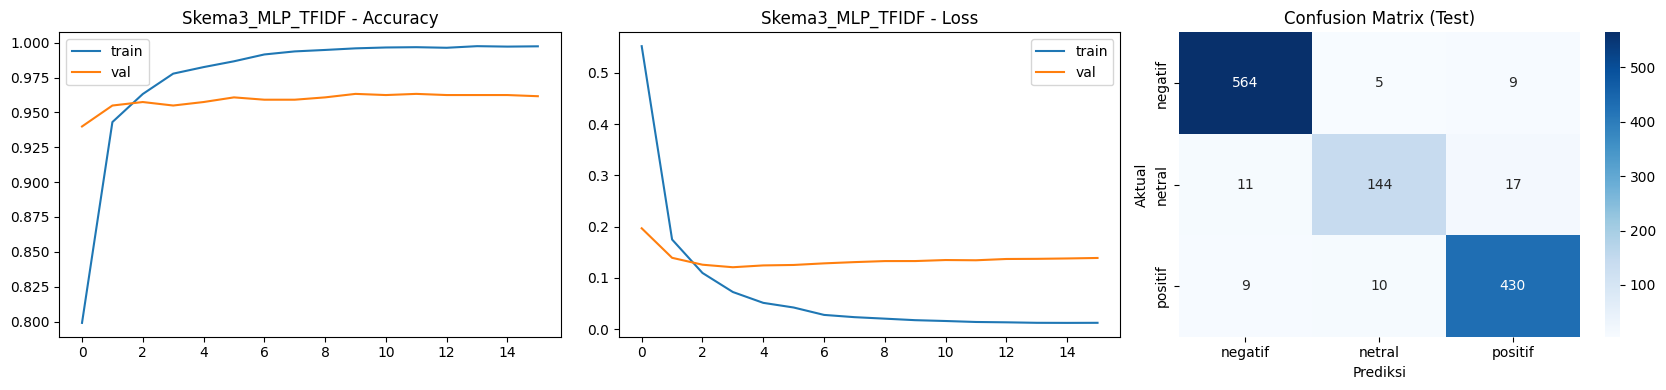

In [ ]:
X_tr, X_va, X_te, y_tr, y_va, y_te, i_te = split_data(0.8, 0.1, 0.1)
tfidf = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Ttr = tfidf.fit_transform(X_tr).toarray().astype('float32')
Tva = tfidf.transform(X_va).toarray().astype('float32')
Tte = tfidf.transform(X_te).toarray().astype('float32')
print('TF-IDF shape:', Ttr.shape)

m3 = models.Sequential([
    layers.Input(shape=(Ttr.shape[1],)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(3, activation='softmax')])
m3.summary()
m3 = train_and_eval('Skema3_MLP_TFIDF', m3, Ttr, y_tr, Tva, y_va, Tte, y_te, i_te)

def tfidf_predict(text):
    p = m3.predict(tfidf.transform([preprocess(text)]).toarray().astype('float32'), verbose=0)[0]
    return CLASS_NAMES[int(p.argmax())], p
predictors['Skema3_MLP_TFIDF'] = tfidf_predict

## 10. Perbandingan Evaluasi Ketiga Skema

In [14]:
summary = pd.DataFrame([
    {'Skema': k, 'Train Acc': v['train_acc'], 'Val Acc': v['val_acc'], 'Test Acc': v['test_acc'], 'Test Macro-F1': v['f1'],
     'Train>92%': v['train_acc'] > 0.92, 'Test>92%': v['test_acc'] > 0.92}
    for k, v in results.items()])
summary['Algoritma'] = ['BiLSTM', 'CNN 1D', 'MLP']
summary['Fitur'] = ['Tokenizer+Embedding', 'Tokenizer+Embedding', 'TF-IDF (1,2)-gram']
summary['Split'] = ['80/10/10', '70/15/15', '80/10/10']
summary = summary[['Skema','Algoritma','Fitur','Split','Train Acc','Val Acc','Test Acc','Test Macro-F1','Train>92%','Test>92%']]
display(summary.style.format({'Train Acc':'{:.4f}','Val Acc':'{:.4f}','Test Acc':'{:.4f}','Test Macro-F1':'{:.4f}'}))
best_name = max(results, key=lambda k: results[k]['test_acc'])
print('Skema terbaik (test acc):', best_name)

,Skema,Algoritma,Fitur,Split,Train Acc,Val Acc,Test Acc,Test Macro-F1,Train>92%,Test>92%
0,Skema1_BiLSTM,BiLSTM,Tokenizer+Embedding,80/10/10,0.9913,0.9825,0.9783,0.9676,True,True
1,Skema2_CNN1D,CNN 1D,Tokenizer+Embedding,70/15/15,0.9893,0.9622,0.9650,0.9528,True,True
2,Skema3_MLP_TFIDF,MLP,"TF-IDF (1,2)-gram",80/10/10,0.9993,0.9633,0.9491,0.9304,True,True


Skema terbaik (test acc): Skema1_BiLSTM


## 11. Error Analysis

Menelaah ulasan data test yang salah diklasifikasi oleh skema terbaik, untuk melihat pola kesalahan
(skor leksikon yang mendekati nol, negasi, slang, atau kata sentimen yang tidak ada di leksikon).

In [15]:
r = results[best_name]
wrong = r['pred'] != r['y_te']
err = pd.DataFrame({
    'ulasan': df['ulasan'].values[r['idx_te']][wrong],
    'skor_leksikon': df['skor'].values[r['idx_te']][wrong],
    'aktual': le.inverse_transform(r['y_te'][wrong]),
    'prediksi': le.inverse_transform(r['pred'][wrong])})
print(f'{best_name}: {wrong.sum()} dari {len(wrong)} data test salah klasifikasi ({wrong.mean():.2%})')
print('Rata-rata |skor| pada data salah:', round(err['skor_leksikon'].abs().mean(), 2),
      '| pada seluruh data:', round(df['skor'].abs().mean(), 2))
display(pd.crosstab(err['aktual'], err['prediksi']))
pd.set_option('display.max_colwidth', 120)
display(err.sample(min(10, len(err)), random_state=SEED))

Skema1_BiLSTM: 26 dari 1199 data test salah klasifikasi (2.17%)
Rata-rata |skor| pada data salah: 0.77 | pada seluruh data: 3.75


prediksi,negatif,netral,positif
aktual,,,
negatif,0,5,1
netral,11,0,3
positif,1,5,0


,ulasan,skor_leksikon,aktual,prediksi
8,"Aman-aman aja sih selama ini buat nyimpen uang, tapi UI nya kaku/lemot banget bikin ga nyaman.",-1,negatif,netral
16,Saya berharap blu bca bisa cepat tanggap seperti bank/layanan ewallet digital lainnya ..apalagi di kasus laporan per...,0,netral,negatif
0,akhirnya nemuin aplikasi yang sesuai sama kebutuhanku. aplikasinya mudah digunakan dan pastinya anti ribet deh! coco...,1,positif,netral
24,"Setiap konfirmasi pin kenapaya selalu ,Hmm sepertinya ada masalah silakan coba lagi ya, padahal sinyal bagus apakah ...",-1,negatif,netral
11,"Bapak Armand berprinsip nyaman dan aman untuk costumer, saya merasa aman dgn blu tapi tdk nyaman dgn motion jadi lam...",0,netral,positif
9,Kapokkk pakai blu by BCA digital... transfer ke rekening sendiri di BCA saldo gak masuk2.. sampai d ulang 2x .. lapo...,0,netral,negatif
13,bagus membantu untuk transaksi tiap hari namun ada kurang nya satu yaitu di blu BCA digital ini agak lemot ya padaha...,0,netral,negatif
1,"Bagi 4 bintang dulu ya, aplikasi udah mantap. Hanya yg kurang tidak punya kartu debit fisik dan virtual soalnya ini ...",1,positif,netral
23,"kecewa bngt 2x ngajuin pinjaman di approve ,tp giliran ngajuin yg ke 3x gk di approve pdhl pembayaran bagus dan gk p...",2,positif,netral
5,Top up pembelian paket data untung nomor lain selalu gagal,0,netral,positif


## 12. Simpan Model dan Artefak

In [16]:
os.makedirs('artifacts', exist_ok=True)
results[best_name]['model'].save(f'artifacts/{best_name}.keras')
with open('artifacts/tokenizer_skema1.pkl', 'wb') as f: pickle.dump((tok1, maxlen1), f)
with open('artifacts/tokenizer_skema2.pkl', 'wb') as f: pickle.dump((tok2, maxlen2), f)
with open('artifacts/tfidf_skema3.pkl', 'wb') as f: pickle.dump(tfidf, f)
with open('artifacts/class_names.pkl', 'wb') as f: pickle.dump(CLASS_NAMES, f)
print('Tersimpan di folder artifacts/')

Tersimpan di folder artifacts/


## 13. Inference (output kelas kategorikal)
Contoh ulasan mencakup ketiga kelas (positif, negatif, netral) dan diuji pada ketiga skema.

In [17]:
contoh = [
    'Aplikasinya bagus banget, transfer cepat dan fiturnya lengkap. Sangat membantu!',
    'Mantap, promo banyak dan pembayaran QRIS lancar.',
    'Parah, login susah terus, aplikasi lambat dan sering error. Kecewa sekali.',
    'Tidak bagus, verifikasi wajah selalu gagal.',
    'Saya baru mencoba aplikasi ini untuk membuka rekening tabungan.',
    'Kemarin saya download aplikasi ini lewat Play Store.',
]
rows = []
for t in contoh:
    row = {'Ulasan': t}
    for name, fn in predictors.items():
        row[name] = fn(t)[0]
    rows.append(row)
pd.set_option('display.max_colwidth', 80)
display(pd.DataFrame(rows))

,Ulasan,Skema1_BiLSTM,Skema2_CNN1D,Skema3_MLP_TFIDF
0,"Aplikasinya bagus banget, transfer cepat dan fiturnya lengkap. Sangat membantu!",positif,positif,positif
1,"Mantap, promo banyak dan pembayaran QRIS lancar.",positif,positif,positif
2,"Parah, login susah terus, aplikasi lambat dan sering error. Kecewa sekali.",negatif,negatif,negatif
3,"Tidak bagus, verifikasi wajah selalu gagal.",negatif,negatif,negatif
4,Saya baru mencoba aplikasi ini untuk membuka rekening tabungan.,netral,netral,netral
5,Kemarin saya download aplikasi ini lewat Play Store.,netral,netral,netral


In [ ]:
def predict_sentiment(text, scheme=None):
    label, prob = predictors[scheme or best_name](text)
    return label, {c: round(float(p), 4) for c, p in zip(CLASS_NAMES, prob)}

for t in contoh:
    print(f'Ulasan : {t}')
    print('Hasil  :', predict_sentiment(t), '\n')

Ulasan : Aplikasinya bagus banget, transfer cepat dan fiturnya lengkap. Sangat membantu!
Hasil  : ('positif', {'negatif': 0.0, 'netral': 0.0, 'positif': 1.0}) 

Ulasan : Mantap, promo banyak dan pembayaran QRIS lancar.
Hasil  : ('positif', {'negatif': 0.0, 'netral': 0.0, 'positif': 1.0}) 

Ulasan : Parah, login susah terus, aplikasi lambat dan sering error. Kecewa sekali.
Hasil  : ('negatif', {'negatif': 1.0, 'netral': 0.0, 'positif': 0.0}) 

Ulasan : Tidak bagus, verifikasi wajah selalu gagal.
Hasil  : ('negatif', {'negatif': 1.0, 'netral': 0.0, 'positif': 0.0}) 

Ulasan : Saya baru mencoba aplikasi ini untuk membuka rekening tabungan.
Hasil  : ('netral', {'negatif': 0.0, 'netral': 1.0, 'positif': 0.0}) 

Ulasan : Kemarin saya download aplikasi ini lewat Play Store.
Hasil  : ('netral', {'negatif': 0.0, 'netral': 1.0, 'positif': 0.0}) 

